## Nombre: Leny Tacuri

## Materia: Machine Learning

## Repositorio: 

# 📔 **Resolución**
Una vez que la nota sea entregada, encontrarás la resolución en este link de notion:

https://www.notion.so/R-DT-and-ensemble-models-1eb05737435780bf924fd27f0fc8c06c?source=copy_link

Recuerda que existen varias formar de solucionar las actividades propuestas en los laboratorios. Toma la resolución entregada como referencia. En caso de que el link de resolución no esté público, solicita acceso en el mismo link de notion.|

# Decision Trees, Random Forest and XGBoost models

Let's import the libraries you will use.

In [2]:
!curl -fL https://raw.githubusercontent.com/mtgca/datasets_public/main/deeplearning.mplstyle -o deeplearning.mplstyle
!curl -fL https://raw.githubusercontent.com/mtgca/datasets_public/main/heart.csv -o heart.csv


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  5013  100  5013    0     0   1465      0  0:00:03  0:00:03 --:--:--  1465 0      0      0 --:--:-- --:--:-- --:--:--     0
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 35921  100 35921    0     0   136k      0 --:--:-- --:--:-- --:--:--  137k


In [4]:
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
#%pip install xgboost --quiet
import xgboost
from xgboost import XGBClassifier
import matplotlib.pyplot as plt
plt.style.use('./deeplearning.mplstyle')

RANDOM_STATE = 55 ## You will pass it to every sklearn call so we ensure reproducibility

# 1. Loading the Dataset

From [Kaggle](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction)

Context
Cardiovascular diseases (CVDs) are the number 1 cause of death globally, taking an estimated 17.9 million lives each year, which accounts for 31% of all deaths worldwide. Heart failure is a common event caused by CVDs and this dataset contains 11 features that can be used to predict a possible heart disease.

People with cardiovascular disease or who are at high cardiovascular risk need early detection and management wherein a machine learning model can be of great help.

You will develop models to predict how likely a particular person is in developint cardiovascular disease, given all the information below.

#### Attribute Information
- Age: age of the patient [years]
- Sex: sex of the patient [M: Male, F: Female]
- ChestPainType: chest pain type [TA: Typical Angina, ATA: Atypical Angina, NAP: Non-Anginal Pain, ASY: Asymptomatic]
- RestingBP: resting blood pressure [mm Hg]
- Cholesterol: serum cholesterol [mm/dl]
- FastingBS: fasting blood sugar [1: if FastingBS > 120 mg/dl, 0: otherwise]
- RestingECG: resting electrocardiogram results [Normal: Normal, ST: having ST-T wave abnormality (T wave inversions and/or ST elevation or depression of > 0.05 mV), LVH: showing probable or definite left ventricular hypertrophy by Estes' criteria]
- MaxHR: maximum heart rate achieved [Numeric value between 60 and 202]
- ExerciseAngina: exercise-induced angina [Y: Yes, N: No]
- Oldpeak: oldpeak = ST [Numeric value measured in depression]
- ST_Slope: the slope of the peak exercise ST segment [Up: upsloping, Flat: flat, Down: downsloping]
- HeartDisease: output class [1: heart disease, 0: Normal]

Let's now load the dataset. As you can see above, the variables:

- Sex
- ChestPainType
- RestingECG
- ExerciseAngina
- ST_Slope

Are *categorical*, so you must one-hot encode them.

In [5]:
# Load the dataset using pandas
df = pd.read_csv("heart.csv")

In [6]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


You must perform some data engineering before working with the models. There are 5 categorical features, so you will use Pandas to one-hot encode them.

## 2. One-hot encoding using Pandas

First you will remove the binary variables, because one-hot encoding them would do nothing to them. To achieve this you will just count how many different values there are in each categorical variable and consider only the variables with 3 or more values.

In [7]:
cat_variables = ['Sex',
'ChestPainType',
'RestingECG',
'ExerciseAngina',
'ST_Slope'
]

As a reminder, one-hot encoding aims to transform a categorical variable with `n` outputs into `n` binary variables.

Pandas has a built-in method to one-hot encode variables, it is the function `pd.get_dummies`. There are several arguments to this function, but here you will use only a few. They are:

 - data: DataFrame to be used
 - prefix: A list with prefixes, so you know which value you are dealing with
 - columns: the list of columns that will be one-hot encoded. 'prefix' and 'columns' must have the same length.

For more information, you can always type `help(pd.get_dummies)` to read the function's full documentation.

In [8]:
# This will replace the columns with the one-hot encoded ones and keep the columns outside 'columns' argument as it is.
df = pd.get_dummies(data = df,
                         prefix = cat_variables,
                         columns = cat_variables)

In [9]:
df.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_F,Sex_M,ChestPainType_ASY,...,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ExerciseAngina_N,ExerciseAngina_Y,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
0,40,140,289,0,172,0.0,0,False,True,False,...,False,False,False,True,False,True,False,False,False,True
1,49,160,180,0,156,1.0,1,True,False,False,...,True,False,False,True,False,True,False,False,True,False
2,37,130,283,0,98,0.0,0,False,True,False,...,False,False,False,False,True,True,False,False,False,True
3,48,138,214,0,108,1.5,1,True,False,True,...,False,False,False,True,False,False,True,False,True,False
4,54,150,195,0,122,0.0,0,False,True,False,...,True,False,False,True,False,True,False,False,False,True


You now will define the final set of variables that will be used by the models you will build in this lab.

In [10]:
var = [x for x in df.columns if x not in 'HeartDisease'] ## Removing our target variable

Note how the number of variables has changed. You started with 11 variables now you have:

In [11]:
print(len(var))

20


# 3. Splitting the Dataset

In this section, you will split our dataset into train and test datasets. You will use the function `train_test_split` from Scikit-learn. Let's just check its arguments.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(df[var], df['HeartDisease'], train_size = 0.8, random_state = RANDOM_STATE)

# We will keep the shuffle = True since our dataset has not any time dependency.

In [13]:
print(f'train samples: {len(X_train)}\ntest samples: {len(X_test)}')
print(f'target proportion: {sum(y_train)/len(y_train):.4f}')

train samples: 734
test samples: 184
target proportion: 0.5518


# 4. Building the Models

## 4.1 Decision Tree

In this section, let's work with the Decision Tree you previously learned, but now using the [Scikit-learn implementation](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html).

There are several hyperparameters in the Decision Tree object from Scikit-learn. You will use only some of them and also you will not perform feature selection nor hyperparameter tuning in this lab (but you are encouraged to do so and compare the results :-) )


The hyperparameters you will use and investigate here is:

 - min_samples_split: The minimum number of samples required to split an internal node. This may prevent overfitting.
 - max_depth: The maximum depth of the tree. This may prevent overfitting.

In [14]:
min_samples_split_list = [2,10, 30, 50, 100, 200, 300, 700] ## If the number is an integer, then it is the actual quantity of samples,
max_depth_list = [1,2, 3, 4, 8, 16, 32, 64, None] # None means that there is no depth limit.

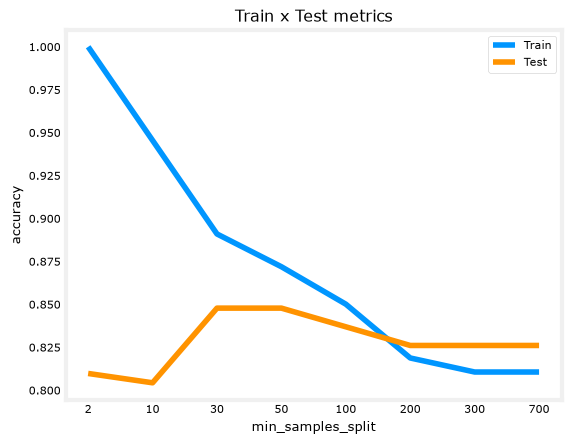

In [15]:
accuracy_list_train = []
accuracy_list_test = []
for min_samples_split in min_samples_split_list:
    # You can fit the model at the same time you define it, because the fit function returns the fitted estimator.
    model = DecisionTreeClassifier(min_samples_split = min_samples_split,
                                   random_state = RANDOM_STATE).fit(X_train,y_train)
    predictions_train = model.predict(X_train) ## The predicted values for the train dataset
    predictions_test = model.predict(X_test) ## The predicted values for the test dataset
    accuracy_train = accuracy_score(predictions_train,y_train)
    accuracy_test = accuracy_score(predictions_test,y_test)
    accuracy_list_train.append(accuracy_train)
    accuracy_list_test.append(accuracy_test)

plt.title('Train x Test metrics')
plt.xlabel('min_samples_split')
plt.ylabel('accuracy')
plt.xticks(ticks = range(len(min_samples_split_list )),labels=min_samples_split_list)
plt.plot(accuracy_list_train)
plt.plot(accuracy_list_test)
plt.legend(['Train','Test'])

Note how increasing the the number of `min_samples_split` decreases the overfit.

Let's do the same experiment with `max_depth`.

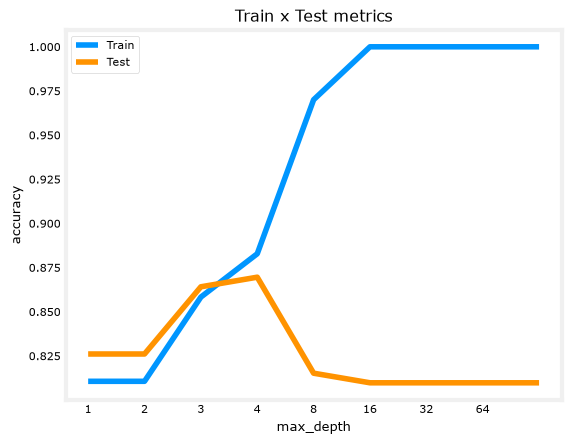

In [16]:
accuracy_list_train = []
accuracy_list_test = []
for max_depth in max_depth_list:
    # You can fit the model at the same time you define it, because the fit function returns the fitted estimator.
    model = DecisionTreeClassifier(max_depth = max_depth,
                                   random_state = RANDOM_STATE).fit(X_train,y_train)
    predictions_train = model.predict(X_train) ## The predicted values for the train dataset
    predictions_test = model.predict(X_test) ## The predicted values for the test dataset
    accuracy_train = accuracy_score(predictions_train,y_train)
    accuracy_test = accuracy_score(predictions_test,y_test)
    accuracy_list_train.append(accuracy_train)
    accuracy_list_test.append(accuracy_test)

plt.title('Train x Test metrics')
plt.xlabel('max_depth')
plt.ylabel('accuracy')
plt.xticks(ticks = range(len(max_depth_list )),labels=max_depth_list)
plt.plot(accuracy_list_train)
plt.plot(accuracy_list_test)
plt.legend(['Train','Test'])

The test accuracy reaches the highest at tree_depth=3. When the allowed depth is smaller, the tree cannot make enough splits to distinguish positives from negatives (having the underfit problem), but when the allowed depth is too high ( >= 5), the tree becomes too specialized to the training set and thus losing accuracy to the test dataset (having the overfit problem). Our final tree model then will have:

- `max_depth = 3`
- `min_samples_split = 50`

In [17]:
decision_tree_model = DecisionTreeClassifier(min_samples_split = 50,
                                             max_depth = 3,
                                             random_state = RANDOM_STATE).fit(X_train,y_train)

In [18]:
print(f"Metrics train:\n\tAccuracy score: {accuracy_score(decision_tree_model.predict(X_train),y_train):.4f}\nMetrics test:\n\tAccuracy score: {accuracy_score(decision_tree_model.predict(X_test),y_test):.4f}")

Metrics train:
	Accuracy score: 0.8583
Metrics test:
	Accuracy score: 0.8641


No sign of overfit, even though the metrics are not that good.

## 4.2 Random Forest

Now let's try the Random Forest algorithm also, using the Scikit-learn implementation. Naturally, all of the above hyperparameters will exist in this algorithm, since it is just an ensemble of Decision Trees, but will have another hyperparameter that you will use, called `n_estimators` which is how many different Decision Trees will be fitted.

Remember that for a Random Forest, you use a subset of the features AND a subset of the training set to train each tree, chosen randomly. In this case, you will use the number of features as you saw in the lecture, which is $\sqrt{n}$ where $n$ is the number of features. However, this can be modified. For further information on the Random Forest hyperparameters, you can run `help(RandomForestClassifier)`.

Another parameter that does not impact on the final result but can speed up the computation is called `n_jobs`. Since the fitting of each tree is independent of each other, it is possible to run parallel fits. So setting `n_jobs` higher will increase how many CPU cores it will use. Note that the numbers very close to the maximum cores of your CPU may impact on the overall performance of your PC and even lead to freezes.

You will run the same script again, but with another parameter, `n_estimators`, where we will choose between 10, 50, and 100. The default is 100.

In [19]:
min_samples_split_list = [2,10, 30, 50, 100, 200, 300, 700]  ## If the number is an integer, then it is the actual quantity of samples,
                                             ## If it is a float, then it is the percentage of the dataset
max_depth_list = [2, 4, 8, 16, 32, 64, None]
n_estimators_list = [10,50,100,500]

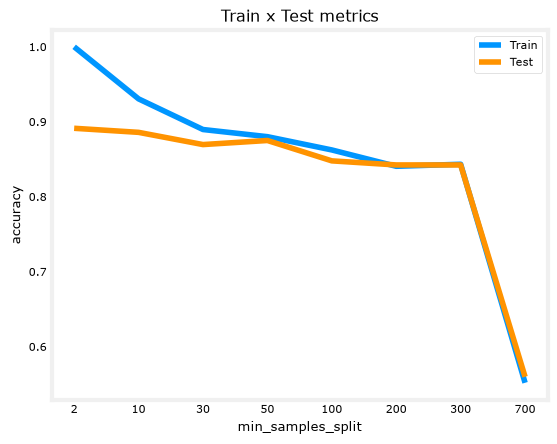

In [20]:
accuracy_list_train = []
accuracy_list_test = []
for min_samples_split in min_samples_split_list:
    # You can fit the model at the same time you define it, because the fit function returns the fitted estimator.
    model = RandomForestClassifier(min_samples_split = min_samples_split,
                                   random_state = RANDOM_STATE).fit(X_train,y_train)
    predictions_train = model.predict(X_train) ## The predicted values for the train dataset
    predictions_test = model.predict(X_test) ## The predicted values for the test dataset
    accuracy_train = accuracy_score(predictions_train,y_train)
    accuracy_test = accuracy_score(predictions_test,y_test)
    accuracy_list_train.append(accuracy_train)
    accuracy_list_test.append(accuracy_test)

plt.title('Train x Test metrics')
plt.xlabel('min_samples_split')
plt.ylabel('accuracy')
plt.xticks(ticks = range(len(min_samples_split_list )),labels=min_samples_split_list)
plt.plot(accuracy_list_train)
plt.plot(accuracy_list_test)
plt.legend(['Train','Test'])

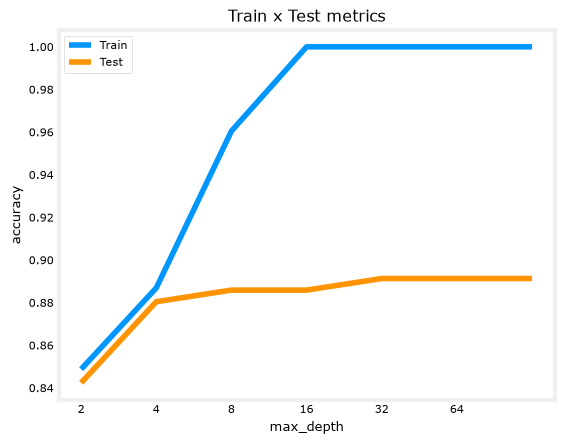

In [21]:
accuracy_list_train = []
accuracy_list_test = []
for max_depth in max_depth_list:
    # You can fit the model at the same time you define it, because the fit function returns the fitted estimator.
    model = RandomForestClassifier(max_depth = max_depth,
                                   random_state = RANDOM_STATE).fit(X_train,y_train)
    predictions_train = model.predict(X_train) ## The predicted values for the train dataset
    predictions_test = model.predict(X_test) ## The predicted values for the test dataset
    accuracy_train = accuracy_score(predictions_train,y_train)
    accuracy_test = accuracy_score(predictions_test,y_test)
    accuracy_list_train.append(accuracy_train)
    accuracy_list_test.append(accuracy_test)

plt.title('Train x Test metrics')
plt.xlabel('max_depth')
plt.ylabel('accuracy')
plt.xticks(ticks = range(len(max_depth_list )),labels=max_depth_list)
plt.plot(accuracy_list_train)
plt.plot(accuracy_list_test)
plt.legend(['Train','Test'])

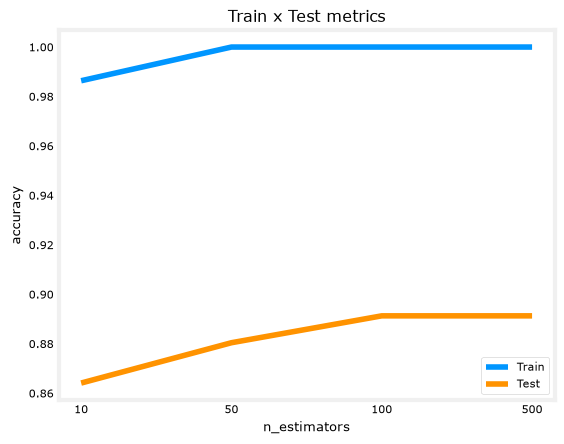

In [22]:
accuracy_list_train = []
accuracy_list_test = []
for n_estimators in n_estimators_list:
    # You can fit the model at the same time you define it, because the fit function returns the fitted estimator.
    model = RandomForestClassifier(n_estimators = n_estimators,
                                   random_state = RANDOM_STATE).fit(X_train,y_train)
    predictions_train = model.predict(X_train) ## The predicted values for the train dataset
    predictions_test = model.predict(X_test) ## The predicted values for the test dataset
    accuracy_train = accuracy_score(predictions_train,y_train)
    accuracy_test = accuracy_score(predictions_test,y_test)
    accuracy_list_train.append(accuracy_train)
    accuracy_list_test.append(accuracy_test)

plt.title('Train x Test metrics')
plt.xlabel('n_estimators')
plt.ylabel('accuracy')
plt.xticks(ticks = range(len(n_estimators_list )),labels=n_estimators_list)
plt.plot(accuracy_list_train)
plt.plot(accuracy_list_test)
plt.legend(['Train','Test'])

Let's then fit a random forest with the following parameters:

 - max_depth: 8
 - min_samples_split: 10
 - n_estimators: 100

In [23]:
random_forest_model = RandomForestClassifier(n_estimators = 100,
                                             max_depth = 8,
                                             min_samples_split = 10, random_state = RANDOM_STATE).fit(X_train,y_train)

In [24]:
print(f"Metrics train:\n\tAccuracy score: {accuracy_score(random_forest_model.predict(X_train),y_train):.4f}\nMetrics test:\n\tAccuracy score: {accuracy_score(random_forest_model.predict(X_test),y_test):.4f}")

Metrics train:
	Accuracy score: 0.9223
Metrics test:
	Accuracy score: 0.8804


You have demonstrated how to look for the best value hyperparameter-by-hyperparameter. However, you should not overlook that as we experiment with one hyperparameter we always have to fix the others at some default values. This makes us only able to tell how the hyperparameter value changes with respect to those defaults. In princple, if you have 4 values to try out in each of the 3 hyperparameters being tuned, you should have a total of 4 x 4 x 4 = 64 combinations, however, the way you are doing will only give us 4 + 4 + 4 = 12 results. To try out all combinations, you can use a sklearn implementation called GridSearchCV, moreover, it has a refit parameter that will automatically refit a model on the best combination so you will not need to program it explicitly. For more on GridSearchCV, please refer to its [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).

## ✅ Activity: Feature Importance analysis with Random Forests

1. Extract feature importance scores from the random_forest_model.

2. Visualize the top 10 most important features using a bar plot.

3. Discuss your observations about the relative importance of different features in predicting heart disease.

,Importancia
ST_Slope_Up,0.188832
ST_Slope_Flat,0.139309
Oldpeak,0.095161
ChestPainType_ASY,0.092835
Cholesterol,0.070121
ExerciseAngina_Y,0.069129
ExerciseAngina_N,0.065919
MaxHR,0.061956
Age,0.047866
RestingBP,0.038282


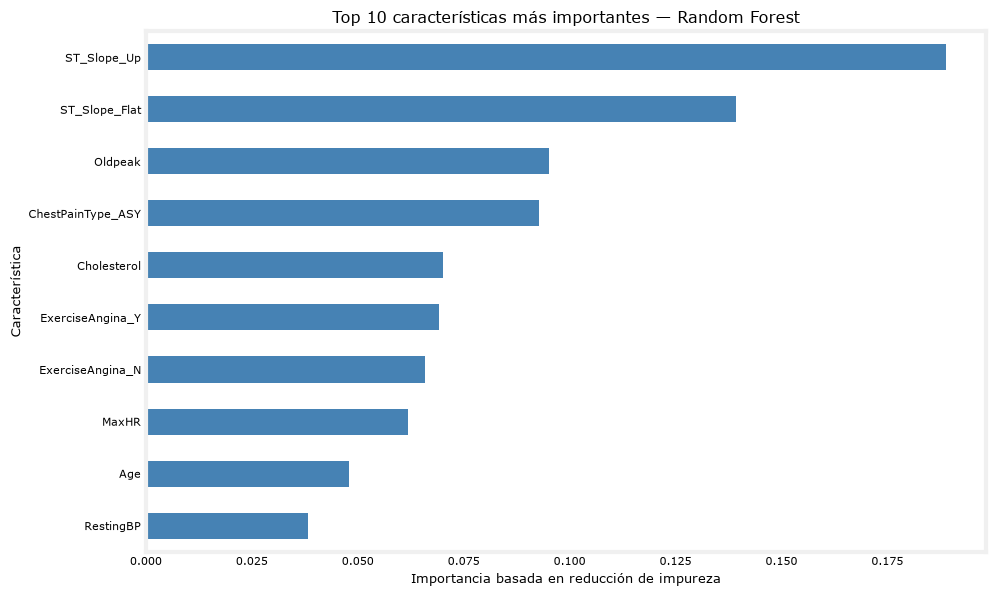

In [25]:
# Extraer las importancias y asociarlas con las columnas de entrenamiento
feature_importance = pd.Series(
    random_forest_model.feature_importances_,
    index=X_train.columns,
    name="Importancia"
).sort_values(ascending=False)

# Mostrar las 10 características más importantes
top_10 = feature_importance.head(10)
display(top_10.to_frame())

# Graficar con la característica más importante arriba
top_10.sort_values().plot.barh(
    figsize=(10, 6),
    color="steelblue"
)

plt.title("Top 10 características más importantes — Random Forest")
plt.xlabel("Importancia basada en reducción de impureza")
plt.ylabel("Característica")
plt.tight_layout()
plt.show()

### Medir mejor, no necesariamente medir más

En el Random Forest entrenado, las características con mayor importancia son `ST_Slope_Up` y `ST_Slope_Flat`, seguidas por `Oldpeak` y `ChestPainType_ASY`. Estas variables aportaron las mayores reducciones de impureza durante la construcción del bosque. Las dos categorías de `ST_Slope` mostradas acumulan aproximadamente un 33 % de la importancia total.

`ST_Slope_Flat` no es una imagen: es una columna que indica si la pendiente del segmento ST del electrocardiograma durante el ejercicio fue clasificada como plana. Es, por tanto, una característica derivada de una medición, convertida en una variable tabular para el modelo.

Otras características, como `Cholesterol`, las categorías de `ExerciseAngina` y `MaxHR`, también contribuyen. `Age` y `RestingBP` presentan menor importancia relativa entre las diez mostradas, lo que no implica que sean irrelevantes. Estas importancias describen cómo el modelo utiliza los datos; no demuestran causalidad ni indican por sí solas si una característica aumenta o disminuye la probabilidad predicha de enfermedad.

El valor práctico de este análisis está en orientar qué información conviene priorizar. En una aplicación real, obtener cada variable puede requerir tiempo, dinero, equipos o esfuerzo. Un modelo con diez características podría predecir igual de bien que uno con veinte, o incluso mejorar si elimina información redundante o ruido. Sin embargo, este resultado debe comprobarse: seleccionar las diez primeras del ranking no garantiza una mejora. Habría que volver a entrenar y comparar ambos conjuntos mediante validación cruzada, realizando la selección dentro de cada partición de entrenamiento y reservando el test para la evaluación final.

También es importante distinguir columnas del modelo de mediciones originales: las veinte columnas de este laboratorio proceden de once variables. Eliminar una categoría generada por one-hot encoding no necesariamente evita obtener la medición de origen. El ahorro real aparece cuando podemos prescindir de una medición o procedimiento completo sin perder una capacidad predictiva relevante.

Así, la importancia de características conecta el aprendizaje automático con una decisión concreta: qué necesitamos medir para resolver bien el problema. El mejor modelo puede ser el que mantiene su rendimiento utilizando información más accesible, económica y sencilla de obtener.

## 4.3 XGBoost

Now, the last model you will test in this lab is the Gradient Boosting model, called XGBoost. As you've seen in the lectures, the boosting methods train several trees, but instead of them being uncorrelated to each other, now the trees are fitted subsequently to minimize the error.

The parameters that this model comprises is the same as the parameters for any decision tree, plus some others, such as the learning rate, which is the size of the step on the Gradient Descent method that the XGBoost uses internally to minimize the error on each train step.

One interesting thing about the XGBoost is that it allows, during the fit, to pass a list evaluation datasets of the form `(X_val,y_val)`, where on each iteration, it measures the cost (or evaluation metric) on the evaluation datasets so that once the cost (or metric) stops to descrease for a number of rounds (called early_stopping_rounds), the training will stop. This is how we can automatically control how many estimators is enough, and how we can avoid overfitting due to too many estimators.

First, let's define a subset of our training set (we should not use the test set here).

In [26]:
n = int(len(X_train)*0.8) ## Let's use 80% to train and 20% to eval

In [27]:
X_train_fit, X_train_eval, y_train_fit, y_train_eval = X_train[:n], X_train[n:], y_train[:n], y_train[n:]

You can then set a large number of estimators, because you can stop if the cost function stops decreasing.

In [28]:
xgb_model = XGBClassifier(n_estimators = 500, learning_rate = 0.1,verbosity = 1, random_state = RANDOM_STATE, early_stopping_rounds=50)
xgb_model.fit(X_train_fit,y_train_fit, eval_set = [(X_train_eval,y_train_eval)])
# Here we must pass a list to the eval_set, because you can have several different tuples ov eval sets. The parameter
# early_stopping_rounds is the number of iterations that it will wait to check if the cost function decreased or not.
# If not, it will stop and get the iteration that returned the lowest metric on the eval set.

[0]	validation_0-logloss:0.63301
[1]	validation_0-logloss:0.59553
[2]	validation_0-logloss:0.56612
[3]	validation_0-logloss:0.54186
[4]	validation_0-logloss:0.52348
[5]	validation_0-logloss:0.50610
[6]	validation_0-logloss:0.49371
[7]	validation_0-logloss:0.48365
[8]	validation_0-logloss:0.47321
[9]	validation_0-logloss:0.46537
[10]	validation_0-logloss:0.45999
[11]	validation_0-logloss:0.45620
[12]	validation_0-logloss:0.45482
[13]	validation_0-logloss:0.44974
[14]	validation_0-logloss:0.44494
[15]	validation_0-logloss:0.44072
[16]	validation_0-logloss:0.44078
[17]	validation_0-logloss:0.43935
[18]	validation_0-logloss:0.44206
[19]	validation_0-logloss:0.44536
[20]	validation_0-logloss:0.44321
[21]	validation_0-logloss:0.44310
[22]	validation_0-logloss:0.44419
[23]	validation_0-logloss:0.44797
[24]	validation_0-logloss:0.44843
[25]	validation_0-logloss:0.45337
[26]	validation_0-logloss:0.45206
[27]	validation_0-logloss:0.45435
[28]	validation_0-logloss:0.45316
[29]	validation_0-loglos

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",50
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


As you can see, even though you passed 500 estimators to fit, the algorithm only fitted 66 because the log-loss used to metrify the training rounds started to increase. In fact, the number of estimators is even less than 66. If you take a closeer look to the metrics, you see that with 16 fitted trees, we achieved the minimum value of the log-loss, and in fact, this is the number of fitted trees in the final model:

In [29]:
xgb_model.best_iteration

17

In [30]:
print(f"Metrics train:\n\tAccuracy score: {accuracy_score(xgb_model.predict(X_train),y_train):.4f}\nMetrics test:\n\tAccuracy score: {accuracy_score(xgb_model.predict(X_test),y_test):.4f}")

Metrics train:
	Accuracy score: 0.9319
Metrics test:
	Accuracy score: 0.8533


You can see that RandomForest achieved the best accuracy, but the results overall were close. And note that we got a very close test metric with XGBoost compared to RandomForest, and we didn't even performed any hyperparameter search! The advantage of XGBoost is that it is faster than the Random Forest and also it has more parameters, therefore you are able to fine-tune the model to achieve even better results.


Congratulations, you have learned how to use Decision Tree, Random Forest from the scikit-learn library and XGBoost!

## ✅ Optimizing XGBoost for Heart Disease Prediction

Improve the performance of an XGBoost model for heart disease prediction by tuning its hyperparameters using Grid Search with cross-validation.

In [31]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold, ParameterGrid
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss

# Cinco particiones que mantienen aproximadamente la proporción de clases
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

param_grid = {
    "n_estimators": [20, 50, 100, 500],
    "learning_rate": [0.03, 0.1, 0.2],
    "max_depth": [2, 3, 6],
    "min_child_weight": [1, 5]
}

# Modelo nuevo: sin early stopping
xgb_search_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=1
)

grid_search = GridSearchCV(
    estimator=xgb_search_model,
    param_grid=param_grid,
    scoring={
        "accuracy": "accuracy",
        "roc_auc": "roc_auc",
        "neg_log_loss": "neg_log_loss"
    },
    refit="accuracy",
    cv=cv,
    n_jobs=4,
    return_train_score=True,
    verbose=1,
    error_score="raise"
)

n_combinations = len(list(ParameterGrid(param_grid)))
print(f"Combinaciones: {n_combinations}")
print(f"Ajustes de CV: {n_combinations * cv.get_n_splits()}")

# Solo utilizamos los datos de entrenamiento para buscar hiperparámetros
grid_search.fit(X_train, y_train)

# GridSearchCV ya lo reentrenó con todo X_train
best_xgb_model = grid_search.best_estimator_

print("\nMejores hiperparámetros:")
print(grid_search.best_params_)
print(f"\nAccuracy promedio de CV: {grid_search.best_score_:.4f}")

# Comparar las cinco mejores configuraciones
cv_results = pd.DataFrame(grid_search.cv_results_)

display(
    cv_results.sort_values("rank_test_accuracy")[
        [
            "params",
            "mean_train_accuracy",
            "mean_test_accuracy",
            "std_test_accuracy",
            "mean_test_roc_auc"
        ]
    ].head()
)

# Evaluación del modelo seleccionado en el test
test_pred = best_xgb_model.predict(X_test)
test_proba = best_xgb_model.predict_proba(X_test)[:, 1]

print("\nResultados en test:")
print(f"Accuracy: {accuracy_score(y_test, test_pred):.4f}")
print(f"ROC AUC:  {roc_auc_score(y_test, test_proba):.4f}")
print(f"Logloss:  {log_loss(y_test, test_proba):.4f}")

Combinaciones: 72
Ajustes de CV: 360
Fitting 5 folds for each of 72 candidates, totalling 360 fits

Mejores hiperparámetros:
{'learning_rate': 0.2, 'max_depth': 3, 'min_child_weight': 1, 'n_estimators': 100}

Accuracy promedio de CV: 0.8719


,params,mean_train_accuracy,mean_test_accuracy,std_test_accuracy,mean_test_roc_auc
58,"{'learning_rate': 0.2, 'max_depth': 3, 'min_ch...",0.981609,0.871895,0.021543,0.925310
45,"{'learning_rate': 0.1, 'max_depth': 6, 'min_ch...",0.930857,0.869211,0.015738,0.931142
62,"{'learning_rate': 0.2, 'max_depth': 3, 'min_ch...",0.957423,0.869201,0.008069,0.925600
56,"{'learning_rate': 0.2, 'max_depth': 3, 'min_ch...",0.909056,0.867869,0.018418,0.931088
53,"{'learning_rate': 0.2, 'max_depth': 2, 'min_ch...",0.906673,0.867813,0.024782,0.930327



Resultados en test:
Accuracy: 0.8859
ROC AUC:  0.9401
Logloss:  0.3210


# ✅ Building a Stacked Ensemble for Heart Disease Prediction

 Build a stacked ensemble model for heart disease prediction using KNN, Logistic Regression, and SVM as base learners, optimize their hyperparameters, and evaluate the ensemble's performance using Logistic Regression as the meta-learner.

 🧠 **Note on SVM (Support Vector Machine)**

Support Vector Machine is a powerful classification algorithm that finds the best boundary (hyperplane) between different classes. However, it might seem complex at first. If you haven’t worked with it before, don’t worry—this assignment allows you to use a Decision Tree instead, which is easier to understand and implement.


In [32]:
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import StackingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss

# 1. Mismas cinco particiones para las búsquedas y el stacking
stack_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# 2. Modelos y grillas pequeñas
model_specs = {
    "knn": (
        KNeighborsClassifier(),
        {
            "model__n_neighbors": [5, 15, 25],
            "model__weights": ["uniform", "distance"]
        }
    ),
    "logistic": (
        LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE
        ),
        {
            "model__C": [0.1, 1, 10]
        }
    ),
    "svm": (
        SVC(
            kernel="rbf",
            probability=True,
            random_state=RANDOM_STATE
        ),
        {
            "model__C": [0.1, 1, 10],
            "model__gamma": ["scale", 0.01]
        }
    )
}

# Guardamos las búsquedas y los mejores modelos para reutilizarlos
base_searches = {}
best_base_models = {}
search_summary = []

# 3. Optimizar cada técnica únicamente con X_train
for name, (estimator, param_grid) in model_specs.items():
    print(f"\nOptimizando {name}...")

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", estimator)
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="accuracy",
        cv=stack_cv,
        n_jobs=4,
        refit=True,
        error_score="raise"
    )

    search.fit(X_train, y_train)

    base_searches[name] = search
    best_base_models[name] = search.best_estimator_

    search_summary.append({
        "Modelo": name,
        "Mejores parámetros": search.best_params_,
        "Accuracy CV": search.best_score_,
        "Desviación CV": search.cv_results_[
            "std_test_score"
        ][search.best_index_]
    })

display(pd.DataFrame(search_summary).set_index("Modelo"))

# 4. Construir el stacking con las configuraciones elegidas
stacking_model = StackingClassifier(
    estimators=[
        (name, clone(model))
        for name, model in best_base_models.items()
    ],
    final_estimator=LogisticRegression(
        C=1.0,
        max_iter=2000,
        random_state=RANDOM_STATE
    ),
    stack_method="predict_proba",
    cv=stack_cv,
    passthrough=False,
    n_jobs=4
)

print("\nEntrenando stacking...")
stacking_model.fit(X_train, y_train)

# 5. Evaluación final: modelos individuales y stacking en el mismo test
models_to_evaluate = {
    **best_base_models,
    "stacking": stacking_model
}

test_results = []

for name, model in models_to_evaluate.items():
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    test_results.append({
        "Modelo": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "ROC AUC": roc_auc_score(y_test, probabilities),
        "Logloss": log_loss(y_test, probabilities)
    })

stacking_results = pd.DataFrame(test_results).set_index("Modelo")

print("\nResultados en test:")
display(stacking_results.round(4))


Optimizando knn...

Optimizando logistic...

Optimizando svm...


/Users/lenytacuri/decision-trees-lab/.venv/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/lenytacuri/decision-trees-lab/.venv/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/lenytacuri/decision-trees-lab/.venv/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/lenytacuri/decision-trees-lab/.venv/lib/python3.11/site-packages/sklearn/svm/_bas

,Mejores parámetros,Accuracy CV,Desviación CV
Modelo,,,
knn,"{'model__n_neighbors': 25, 'model__weights': '...",0.870543,0.021710
logistic,{'model__C': 0.1},0.867850,0.003204
svm,"{'model__C': 1, 'model__gamma': 0.01}",0.866471,0.012770


/Users/lenytacuri/decision-trees-lab/.venv/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



Entrenando stacking...


/Users/lenytacuri/decision-trees-lab/.venv/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/lenytacuri/decision-trees-lab/.venv/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/lenytacuri/decision-trees-lab/.venv/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/lenytacuri/decision-trees-lab/.venv/lib/python3.11/site-packages/sklearn/svm/_bas


Resultados en test:


,Accuracy,ROC AUC,Logloss
Modelo,,,
knn,0.8804,0.9398,0.6592
logistic,0.8696,0.9348,0.3187
svm,0.8967,0.9372,0.3091
stacking,0.8804,0.9389,0.3039


# ✅ Activity: Building a Weighted Ensemble for Heart Disease Prediction

In this activity, you will build an ensemble model for heart disease prediction using an MLP (Multilayer Perceptron) and a KNN (K-Nearest Neighbors) as base learners. You will optimize both base learners using Grid Search and then combine their predictions using a weighted average,  with 0.75 weight for the MLP and 0.25 weight for the KNN.

What is the role of the weights in the weighted average prediction?

Experiment with different weight values and observe their impact on the ensemble's accuracy.

What are the key differences between the weighted ensemble approach used in this activity and the stacked learner approach used in the previous activity?



Fitting 5 folds for each of 8 candidates, totalling 40 fits
Mejores parámetros MLP: {'model__alpha': 0.0001, 'model__hidden_layer_sizes': (64, 32), 'model__learning_rate_init': 0.01}
Mejor accuracy CV MLP: 0.8596
Mejores parámetros KNN: {'model__n_neighbors': 25, 'model__weights': 'distance'}


,Peso MLP,Peso KNN,Accuracy OOF,Logloss OOF
0,0.00,1.00,0.8706,0.3787
1,0.25,0.75,0.8801,0.3346
2,0.50,0.50,0.8719,0.3361
3,0.75,0.25,0.8597,0.3453
4,1.00,0.00,0.8597,0.3737


Pesos elegidos: MLP=0.25, KNN=0.75


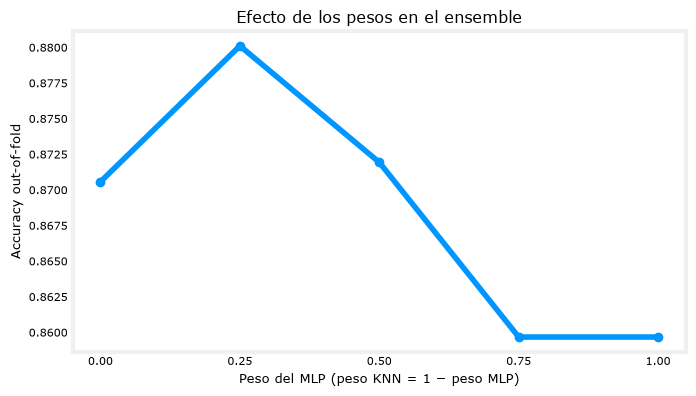


Resultados finales en test:


,Accuracy,ROC AUC,Logloss
Modelo,,,
MLP,0.8859,0.9476,0.3103
KNN,0.8804,0.9398,0.6592
Ensemble 0.75 / 0.25,0.8859,0.9467,0.3033
Ensemble elegido (0.25 / 0.75),0.8913,0.9435,0.3191


In [33]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import (
    GridSearchCV, StratifiedKFold, cross_val_predict
)
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss

# 1. Validación cruzada
weighted_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# 2. Optimizar MLP con escalado dentro del pipeline
mlp_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", MLPClassifier(
        activation="relu",
        solver="adam",
        max_iter=1000,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=30,
        random_state=RANDOM_STATE
    ))
])

mlp_grid = {
    "model__hidden_layer_sizes": [(32,), (64, 32)],
    "model__alpha": [0.0001, 0.01],
    "model__learning_rate_init": [0.001, 0.01]
}

mlp_search = GridSearchCV(
    mlp_pipeline,
    param_grid=mlp_grid,
    scoring="accuracy",
    cv=weighted_cv,
    n_jobs=4,
    refit=True,
    verbose=1,
    error_score="raise"
)

mlp_search.fit(X_train, y_train)

best_mlp = mlp_search.best_estimator_
best_knn = best_base_models["knn"]  # De la actividad anterior

print("Mejores parámetros MLP:", mlp_search.best_params_)
print(f"Mejor accuracy CV MLP: {mlp_search.best_score_:.4f}")
print("Mejores parámetros KNN:", base_searches["knn"].best_params_)

# 3. Predicciones out-of-fold para explorar pesos sin utilizar X_test
oof_mlp = cross_val_predict(
    best_mlp, X_train, y_train,
    cv=weighted_cv,
    method="predict_proba",
    n_jobs=4
)[:, 1]

oof_knn = cross_val_predict(
    best_knn, X_train, y_train,
    cv=weighted_cv,
    method="predict_proba",
    n_jobs=4
)[:, 1]

# Los extremos permiten comparar también cada modelo por separado
weight_results = []

for w in [0.0, 0.25, 0.5, 0.75, 1.0]:
    probabilities = w * oof_mlp + (1 - w) * oof_knn
    predictions = (probabilities >= 0.5).astype(int)

    weight_results.append({
        "Peso MLP": w,
        "Peso KNN": 1 - w,
        "Accuracy OOF": accuracy_score(y_train, predictions),
        "Logloss OOF": log_loss(y_train, probabilities)
    })

weight_results = pd.DataFrame(weight_results)
display(weight_results.round(4))

# Elegir por accuracy; desempatar con menor logloss
selected = weight_results.sort_values(
    ["Accuracy OOF", "Logloss OOF"],
    ascending=[False, True]
).iloc[0]

best_weight = float(selected["Peso MLP"])
print(f"Pesos elegidos: MLP={best_weight}, KNN={1 - best_weight}")

plt.figure(figsize=(7, 4))
plt.plot(
    weight_results["Peso MLP"],
    weight_results["Accuracy OOF"],
    marker="o"
)
plt.xticks(weight_results["Peso MLP"])
plt.xlabel("Peso del MLP (peso KNN = 1 − peso MLP)")
plt.ylabel("Accuracy out-of-fold")
plt.title("Efecto de los pesos en el ensemble")
plt.tight_layout()
plt.show()

# 4. Evaluación final: los modelos ya están ajustados con todo X_train
test_mlp = best_mlp.predict_proba(X_test)[:, 1]
test_knn = best_knn.predict_proba(X_test)[:, 1]

test_probabilities = {
    "MLP": test_mlp,
    "KNN": test_knn,
    "Ensemble 0.75 / 0.25": 0.75 * test_mlp + 0.25 * test_knn,
    f"Ensemble elegido ({best_weight:.2f} / {1-best_weight:.2f})":
        best_weight * test_mlp + (1 - best_weight) * test_knn
}

weighted_test_results = []

for name, probabilities in test_probabilities.items():
    weighted_test_results.append({
        "Modelo": name,
        "Accuracy": accuracy_score(
            y_test, (probabilities >= 0.5).astype(int)
        ),
        "ROC AUC": roc_auc_score(y_test, probabilities),
        "Logloss": log_loss(y_test, probabilities)
    })

print("\nResultados finales en test:")
display(
    pd.DataFrame(weighted_test_results)
    .set_index("Modelo")
    .round(4)
)

| Ensemble ponderado | Stacking anterior |
|---|---|
| Combinamos probabilidades mediante un promedio con pesos explícitos. | Una regresión logística aprende cómo combinar las probabilidades. |
| Los pesos son no negativos y suman 1. | Los coeficientes pueden ser negativos y no tienen que sumar 1; también hay un intercepto. |
| Exploramos unas pocas mezclas y elegimos con datos de entrenamiento. | Entrenamos un meta-modelo con las predicciones OOF y las etiquetas reales. |

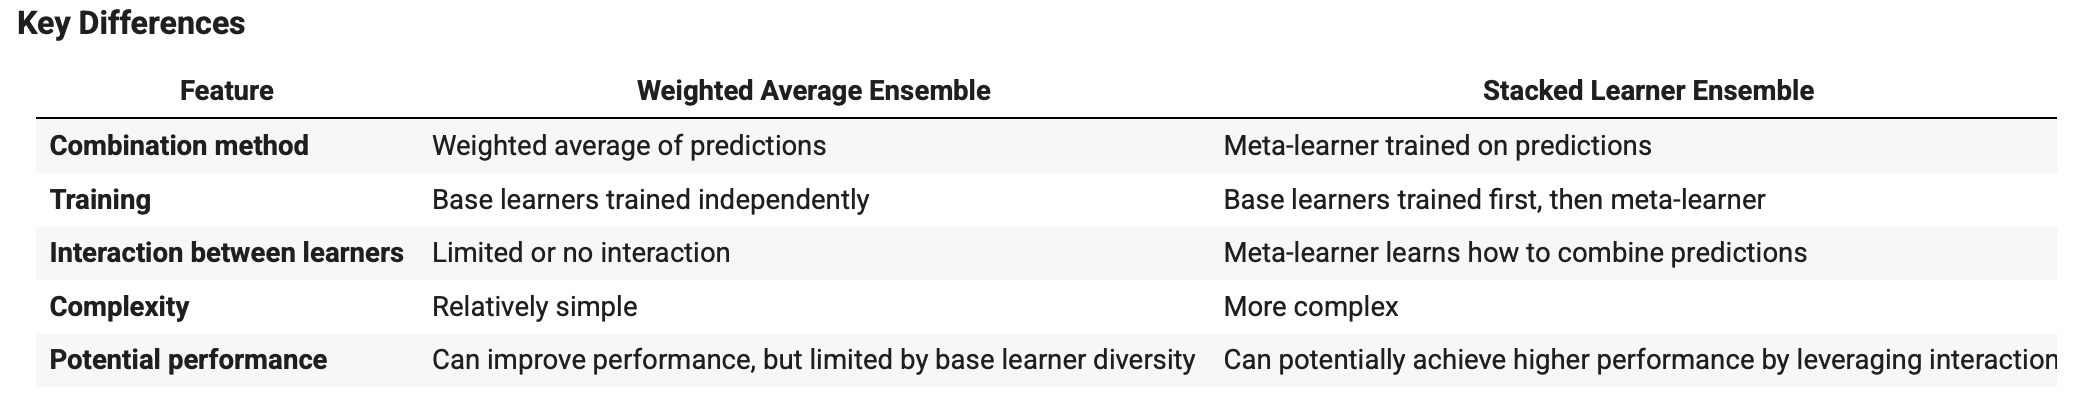

# ✅ Building and Comparing Voting Strategies in Ensemble Models



Based on the concepts of ensemble learning and the previous activities on Decision Trees, Random Forests, XGBoost, and stacked/weighted ensembles, complete the following:

1.  **Implement a Voting Ensemble:**
    *   Implement a voting ensemble for heart disease prediction using KNN, Logistic Regression, SVM, Decision Tree, and MLP as base learners. Check the class `VotingClassifier`. 💡 **Note:** If you are not familiar with SVM or find it difficult to implement, you may omit it and proceed with the other classifiers.
    *   Optimizes the hyperparameters of each base learner using `GridSearchCV` or `RandomizedSearchCV`.
    *   Use both the "hard voting" and "soft voting" ensembles.

2.  **Compare Hard vs. Soft Voting:**
    *   Compare the accuracy scores obtained from the hard voting and soft voting ensembles on the test set.
    *   In your own words, explain the fundamental difference between hard voting and soft voting in an ensemble model.
    *   Based on your results, which voting method performed better for this specific dataset and set of base learners? Can you hypothesize why this might be the case?

3.  **Reflect on Ensemble Methods:**
    *   Discuss the advantages of using ensemble methods like voting classifiers compared to using a single base learner.
    *   Consider the previous activities on stacked and weighted ensembles. How do these approaches differ from the voting ensemble implemented in this homework? What are potential benefits or drawbacks of each approach?


In [ ]:
#your code here

# ✅ Auto Machine Learning (AutoML) using AutoGluon

**What is AutoML?**

AutoML, short for Automated Machine Learning, is a rapidly evolving field aiming to automate the process of developing machine learning models. Traditionally, building a model involves manual steps like data preprocessing, feature engineering, model selection, hyperparameter tuning, and evaluation, requiring significant expertise and time.
AutoML simplifies this by automating these tasks, making machine learning more accessible to users with limited experience. AutoML tools use advanced algorithms and techniques to automatically explore different model architectures and hyperparameter settings, finding the best model for a given dataset and task.

**Benefits of AutoML:**

**Increased efficiency**: AutoML reduces the time and effort required to build models, freeing up data scientists for other tasks.

**Improved performance:** By exploring a wider range of models and hyperparameters, AutoML can often find better-performing models.

**Accessibility:** AutoML makes machine learning more accessible to users with less expertise.

**Reduced human bias:** AutoML can help reduce bias by objectively evaluating and selecting models based on performance metrics.

**Criticisms of AutoML:**

Despite its advantages, AutoML also faces some criticisms:

**Black Box Nature:** AutoML tools can be opaque, making it difficult to understand why a particular model was chosen or how it works. This lack of transparency can be a concern, especially in sensitive applications.

**Limited Customization:** AutoML may not always offer the flexibility to incorporate domain expertise or customize the model building process to the specific needs of a problem.

**Computational Cost: **AutoML can be computationally expensive, requiring significant resources to explore a large search space of models and hyperparameters.

**Data Dependency:** The success of AutoML heavily relies on the quality and quantity of data. If the data is noisy, incomplete, or biased, AutoML may not produce reliable results.

**Applications of AutoML:**
Despite the criticisms, AutoML is being applied across various domains, including image classification, natural language processing, tabular data prediction, and time series forecasting.

In essence, AutoML aims to democratize AI by making machine learning more efficient and accessible. However, it's important to be aware of its limitations and use it judiciously, combining its power with human expertise for optimal results.

**Activity:**

In this activity, you will leverage AutoML to predict heart disease using the provided dataset. Explore the AutoML library AutoGluon to automate the model building process, including data preprocessing, model selection, and hyperparameter tuning. Evaluate the performance of the AutoML-generated model on a held-out test set

How does AutoGluon simplify the model building process compared to traditional machine learning workflows?

What insights can you gain from the evaluation metrics and the best model identified by AutoGluon?

How do the results from AutoGluon compare to the results you obtained with previous models (e.g., the weighted ensemble)?


In [ ]:
!pip install autogluon.tabular --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 352.2/352.2 kB 17.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 266.2/266.2 kB 18.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.1/64.1 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.2/68.2 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.3/13.3 MB 98.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.9/139.9 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.5/13.5 MB 100.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.8/84.8 kB 6.9 MB/s eta 0:00:00


In [ ]:
#your code here

In [ ]:
print(feature_importance)

# ✅ Exploring TabPFN for Heart Disease Prediction

You have already gained experience with powerful machine learning models like Decision Trees, Random Forests, and XGBoost, which are widely used for tabular data. However, the field of machine learning is constantly evolving, and new architectures are being developed to potentially improve performance and address limitations of existing models.

One such model is TabPFN (Tabular Feature Processing Network). Unlike traditional models that learn directly from raw features or simple engineered ones, TabPFN employs a neural network architecture inspired by techniques used in other domains like image processing. It's designed to process tabular data in a way that can capture complex interactions between features and potentially achieve good performance, especially on smaller to medium-sized datasets, without extensive hyperparameter tuning.
TabPFN's importance lies in its potential to:

* Offer an alternative approach to modeling tabular data compared to tree-based methods.
* Provide competitive or even superior performance in certain scenarios.
* Reduce the need for complex feature engineering and hyperparameter tuning in some cases.

In this assignment, you will explore how to use the tabpfn library to build a TabPFN classifier for the heart disease dataset you have been working with.

**Instructions:**

1. Install the tabpfn library in your Colab notebook using pip. Please read the repo https://github.com/PriorLabs/TabPFN
2. Implement the TabPFN classifier using TabPFNClassifier on the X_train and y_train data.
3. Predict class labels and probabilities on the X_test data.
4. Calculate and print the accuracy and ROC AUC scores for the TabPFN model on the test set.

**Reflective Questions:**

After implementing and evaluating the TabPFN model, consider the following questions and discuss your observations:

1. **Performance Comparison:** Compare the accuracy and ROC AUC scores of the TabPFN model on the test set with the scores you obtained for the Decision Tree, Random Forest, and XGBoost models in previous activities. Which model performed best on this dataset? Are the differences significant?

2. **Ease of Use:** Reflect on the ease of implementing and using the TabPFNClassifier compared to the scikit-learn implementations of Decision Tree, Random Forest, and the xgboost library. Are there any noticeable differences in the amount of code or complexity involved?

3. **Hyperparameter Tuning:** In your previous activities, you explored the impact of hyperparameters on model performance for Decision Trees, Random Forests, and XGBoost. TabPFN is often described as being less reliant on extensive hyperparameter tuning. Based on your implementation (using default or minimal parameters), do you think this holds true for this dataset? Why or why not?

4. **Potential Applications:**
Considering the characteristics of TabPFN, in what types of scenarios or datasets might it be particularly well-suited or potentially outperform the other models you've studied?

5. **Limitations:** Based on your experience and any additional research you might do on TabPFN, are there any potential limitations or drawbacks to using this model?



In [ ]:
# your code here

# ✅ Activity: Building a Bagging Ensemble with Optimized SVMs.

In this activity, you will build a Bagging ensemble with optimized SVMs (RBF kernel) as base learners, specifically using 20 of these base learners. Use BaggingClassifier Class.  Compare the accuracy of this Bagging model (with 20 estimators) to the optimized individual SVM and the previous ensemble models.

🧩 **Alternative Option:** If you are not familiar with SVMs or face implementation difficulties, you may use Decision Trees or KNN instead as base learners in the Bagging ensemble.

In [ ]:
#your code here